# RNN — DBO na entrada com 10 DBO medidas anteriores

A DBO na entrada (`DBO-E`) continua sendo o alvo. A diferença em relação à RNN de DQO e SST é a fila: cada exemplo guarda 10 valores reais de DBO, os dez dias anteriores disponíveis. A DBO do dia estimado não entra na fila.

A DQO (`DQO-E`) e o SST (`SS-E`) do dia estimado continuam disponíveis, e entram só na saída, junto com o estado final. São as medidas desse dia. As leituras anteriores de DQO e SST não são guardadas.

Dias sem uma das três medidas saem da série. Não há interpolação. A ordem da data importa, porque as 10 DBO são uma fila.


In [1]:
from pathlib import Path
import sys
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.figsize": (6.2, 4.6),
    "axes.grid": True,
    "grid.color": "0.85",
    "grid.linewidth": 0.6,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "medium",
})

COR = "#1f4e79"
COR_REF = "#c45c26"
SEMENTE = 42
JANELA = 10
ENTRADAS = ["DQO-E", "SS-E"]
ALVO = "DBO-E"
np.random.seed(SEMENTE)


def raiz_repositorio() -> Path:
    aqui = Path.cwd().resolve()
    for candidato in [aqui, *aqui.parents]:
        if (candidato / "data" / "water-treatment-plant" / "water-treatment.data").exists():
            return candidato
    raise FileNotFoundError("Repositório SoftSensor não encontrado.")


RAIZ = raiz_repositorio()
sys.path.insert(0, str(RAIZ / "modelo"))
from dados import carregar

FIGURAS = RAIZ / "docs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)


## Série da entrada

As 10 DBO são os dias completos anteriores na série ordenada. Um intervalo no calendário continua sendo um intervalo: a leitura anterior é a última disponível, não um valor interpolado.


In [2]:
bruto = carregar()
tabela = (
    bruto.dropna(subset=[ALVO, *ENTRADAS])
    .loc[:, ["data", ALVO, *ENTRADAS]]
    .sort_values("data")
    .reset_index(drop=True)
)
intervalo = tabela["data"].diff().dt.days

print(f"dias no arquivo: {len(bruto)}")
print(f"dias com DBO, DQO e SST na entrada: {len(tabela)}")
print(f"intervalo mediano entre leituras, em dias: {intervalo.median():.0f}")
print(f"leituras separadas por mais de um dia: {int((intervalo > 1).sum())}")
print(f"maior intervalo, em dias: {intervalo.max():.0f}")
tabela[[ALVO, *ENTRADAS]].describe().round(2)


dias no arquivo: 527
dias com DBO, DQO e SST na entrada: 498
intervalo mediano entre leituras, em dias: 1
leituras separadas por mais de um dia: 116
maior intervalo, em dias: 32


,DBO-E,DQO-E,SS-E
count,498.00,498.00,498.00
mean,188.72,405.36,228.74
std,62.28,119.99,139.12
min,31.00,81.00,98.00
25%,146.25,324.25,170.00
50%,182.50,397.50,198.00
75%,223.00,472.75,243.50
max,438.00,941.00,2008.00


## Janela, treino e validação cruzada

O alvo do índice `t` usa `DBO[t-10]` até `DBO[t-1]`, e a DQO e o SST do próprio dia `t`. Oitenta por cento dos dias, os mais antigos, formam o treino. Os 20% mais recentes ficam para o teste. A fila não é embaralhada.

A validação cruzada, só no treino, é temporal (`TimeSeriesSplit`, 5 partições). O `StandardScaler` da DBO, da DQO e do SST usa apenas as janelas de treino daquela partição. A DBO da fila e a DBO alvo compartilham o mesmo scaler. O critério é o MAE na unidade original da DBO.


In [3]:
def montar_janelas(serie, tamanho, inicio, fim):
    """Alvo em [inicio, fim). A fila é a DBO real dos `tamanho` dias anteriores."""
    dqo = serie["DQO-E"].to_numpy(dtype=float)
    sst = serie["SS-E"].to_numpy(dtype=float)
    dbo = serie[ALVO].to_numpy(dtype=float)
    datas = serie["data"].to_numpy()
    xs, dias, ys, fins, vaos = [], [], [], [], []
    for t in range(max(inicio, tamanho), fim):
        a = t - tamanho
        xs.append(dbo[a:t])
        dias.append([dqo[t], sst[t]])
        ys.append(dbo[t])
        fins.append(datas[t])
        vaos.append((datas[t - 1] - datas[a]) / np.timedelta64(1, "D"))
    return (
        np.asarray(xs, dtype=float)[:, :, None],
        np.asarray(dias, dtype=float),
        np.asarray(ys, dtype=float),
        np.asarray(fins),
        np.asarray(vaos, dtype=float),
    )


corte = int(len(tabela) * 0.8)
X_treino, dia_treino, y_treino, data_treino, vao_treino = montar_janelas(tabela, JANELA, 0, corte)
X_teste, dia_teste, y_teste, data_teste, vao_teste = montar_janelas(tabela, JANELA, corte, len(tabela))

print(f"dias de treino: {corte}")
print(f"dias de teste: {len(tabela) - corte}")
print(f"janelas de treino: {len(X_treino)}")
print(f"janelas de teste: {len(X_teste)}")
print(f"primeiro dia de teste: {pd.Timestamp(data_teste[0]).date()}")
print(f"último dia de teste: {pd.Timestamp(data_teste[-1]).date()}")
print(f"DBO média no treino: {y_treino.mean():.2f}")
print(f"DBO média no teste: {y_teste.mean():.2f}")
print(f"desvio da DBO no treino: {y_treino.std():.2f}")
print(f"desvio da DBO no teste: {y_teste.std():.2f}")
print(f"vão mediano das 10 DBO anteriores, em dias: {np.median(np.concatenate([vao_treino, vao_teste])):.0f}")
print(f"vão máximo das 10 DBO anteriores, em dias: {np.max(np.concatenate([vao_treino, vao_teste])):.0f}")
dbo = tabela[ALVO].to_numpy(dtype=float)
print(f"formato da fila de DBO: {X_treino.shape[1:]}")
print(f"primeira fila são as 10 DBO anteriores ao alvo: {np.allclose(X_treino[0, :, 0], dbo[:JANELA])}")
print(f"primeiro alvo é a DBO seguinte: {np.isclose(y_treino[0], dbo[JANELA])}")
print(f"fila de teste usa as últimas DBO do treino: {np.allclose(X_teste[0, :, 0], dbo[corte - JANELA:corte])}")


dias de treino: 398
dias de teste: 100
janelas de treino: 388
janelas de teste: 100
primeiro dia de teste: 1991-05-29
último dia de teste: 1991-10-29
DBO média no treino: 194.93
DBO média no teste: 163.77
desvio da DBO no treino: 66.28
desvio da DBO no teste: 36.63
vão mediano das 10 DBO anteriores, em dias: 11
vão máximo das 10 DBO anteriores, em dias: 43
formato da fila de DBO: (10, 1)
primeira fila são as 10 DBO anteriores ao alvo: True
primeiro alvo é a DBO seguinte: True
fila de teste usa as últimas DBO do treino: True


## RNN

A rede de Elman lê as 10 DBO em ordem, com tangente hiperbólica, e guarda só o estado final. A saída linear junta esse estado à DQO e ao SST do dia estimado. O treino é Adam com retropropagação no tempo. A grade escolhe o tamanho do estado e a taxa de aprendizado, e para quando o MAE da partição de validação deixa de cair.


In [4]:
def iniciar(oculto, semente):
    rng = np.random.default_rng(semente)
    base = rng.normal(size=(oculto, oculto))
    q, r = np.linalg.qr(base)
    return {
        "W_xh": rng.normal(0, 1.0, size=(oculto, 1)),
        "W_hh": q * np.sign(np.diag(r)),
        "b_h": np.zeros(oculto),
        "W_hy": rng.normal(0, np.sqrt(1 / (oculto + 2)), size=(oculto + 2,)),
        "b_y": np.zeros(()),
    }


def adiante(X, dia, params):
    n, passos, _ = X.shape
    oculto = params["b_h"].shape[0]
    estados = []
    h = np.zeros((n, oculto))
    for t in range(passos):
        z = X[:, t] @ params["W_xh"].T + h @ params["W_hh"].T + params["b_h"]
        h = np.tanh(z)
        estados.append(h)
    combinado = np.column_stack([h, dia])
    return combinado @ params["W_hy"] + params["b_y"], estados


def retropropagar(X, dia, estados, y, alvo, params, cortar=True):
    n, passos, _ = X.shape
    oculto = params["b_h"].shape[0]
    dy = 2 * (y - alvo) / n
    combinado = np.column_stack([estados[-1], dia])
    grads = {
        "W_hy": combinado.T @ dy,
        "b_y": np.array(dy.sum()),
        "W_xh": np.zeros_like(params["W_xh"]),
        "W_hh": np.zeros_like(params["W_hh"]),
        "b_h": np.zeros_like(params["b_h"]),
    }
    dh = dy[:, None] * params["W_hy"][:oculto]
    for t in reversed(range(passos)):
        h = estados[t]
        anterior = estados[t - 1] if t else np.zeros((n, oculto))
        dz = dh * (1 - h ** 2)
        grads["W_xh"] += dz.T @ X[:, t]
        grads["W_hh"] += dz.T @ anterior
        grads["b_h"] += dz.sum(axis=0)
        dh = dz @ params["W_hh"]
    if cortar:
        norma = np.sqrt(sum(np.sum(g * g) for g in grads.values()))
        if norma > 1:
            for nome in grads:
                grads[nome] *= 1 / norma
    return grads


def passo_adam(params, grads, momento, velocidade, t, taxa):
    t += 1
    for nome in params:
        momento[nome] = 0.9 * momento[nome] + 0.1 * grads[nome]
        velocidade[nome] = 0.999 * velocidade[nome] + 0.001 * grads[nome] ** 2
        m = momento[nome] / (1 - 0.9 ** t)
        v = velocidade[nome] / (1 - 0.999 ** t)
        params[nome] = params[nome] - taxa * m / (np.sqrt(v) + 1e-8)
    return t


def escalar(X_tr, dia_tr, y_tr):
    sy = StandardScaler().fit(np.concatenate([X_tr.ravel(), y_tr]).reshape(-1, 1))
    sx = StandardScaler().fit(dia_tr)
    Xn = sy.transform(X_tr.reshape(-1, 1)).reshape(X_tr.shape)
    yn = sy.transform(y_tr.reshape(-1, 1)).ravel()
    dn = sx.transform(dia_tr)
    return Xn, dn, yn, sx, sy


def ajustar(X_tr, dia_tr, y_tr, X_va, dia_va, y_va, oculto, taxa, semente, epocas=120, paciencia=12):
    Xtr, dtr, ytr, sx, sy = escalar(X_tr, dia_tr, y_tr)
    Xva = sy.transform(X_va.reshape(-1, 1)).reshape(X_va.shape)
    dva = sx.transform(dia_va)
    params = iniciar(oculto, semente)
    momento = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    velocidade = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    rng = np.random.default_rng(semente)
    melhor = copy.deepcopy(params)
    melhor_mae = np.inf
    melhor_epoca = 0
    espera = 0
    t = 0
    for epoca in range(1, epocas + 1):
        ordem = rng.permutation(len(Xtr))
        for inicio in range(0, len(Xtr), 64):
            idx = ordem[inicio:inicio + 64]
            y_lote, estados = adiante(Xtr[idx], dtr[idx], params)
            grads = retropropagar(Xtr[idx], dtr[idx], estados, y_lote, ytr[idx], params)
            t = passo_adam(params, grads, momento, velocidade, t, taxa)
        y_val, _ = adiante(Xva, dva, params)
        previsto = sy.inverse_transform(y_val.reshape(-1, 1)).ravel()
        mae = mean_absolute_error(y_va, previsto)
        if mae < melhor_mae - 1e-4:
            melhor_mae = mae
            melhor_epoca = epoca
            melhor = copy.deepcopy(params)
            espera = 0
        else:
            espera += 1
            if espera >= paciencia:
                break
    return melhor, sx, sy, float(melhor_mae), int(melhor_epoca)


def prever(params, sx, sy, X, dia):
    Xn = sy.transform(X.reshape(-1, 1)).reshape(X.shape)
    dn = sx.transform(dia)
    y, _ = adiante(Xn, dn, params)
    return sy.inverse_transform(y.reshape(-1, 1)).ravel()


def perda(params, X, dia, alvo):
    y, _ = adiante(X, dia, params)
    return float(np.mean((y - alvo) ** 2))


rng_chk = np.random.default_rng(0)
X_chk = rng_chk.normal(size=(5, JANELA, 1))
dia_chk = rng_chk.normal(size=(5, 2))
y_chk = rng_chk.normal(size=(5,))
params_chk = iniciar(3, 1)
y_hat, estados_chk = adiante(X_chk, dia_chk, params_chk)
grads_chk = retropropagar(X_chk, dia_chk, estados_chk, y_hat, y_chk, params_chk, cortar=False)
pior = 0.0
eps = 1e-5
for nome, valor in params_chk.items():
    plano = valor.ravel()
    grad = grads_chk[nome].ravel()
    for i in range(plano.size):
        original = plano[i]
        plano[i] = original + eps
        mais = perda(params_chk, X_chk, dia_chk, y_chk)
        plano[i] = original - eps
        menos = perda(params_chk, X_chk, dia_chk, y_chk)
        plano[i] = original
        numerico = (mais - menos) / (2 * eps)
        pior = max(pior, abs(numerico - grad[i]))
print(f"maior diferença entre gradiente analítico e numérico: {pior:.2e}")
if pior > 1e-4:
    raise RuntimeError("Gradiente da RNN não confere com a diferença finita.")


maior diferença entre gradiente analítico e numérico: 6.03e-10


In [5]:
grade = []
partes = TimeSeriesSplit(n_splits=5)
for oculto in (8, 16, 32):
    for taxa in (1e-3, 1e-2):
        maes, epocas = [], []
        for i, (tr, va) in enumerate(partes.split(X_treino), start=1):
            _, _, _, mae, epoca = ajustar(
                X_treino[tr], dia_treino[tr], y_treino[tr],
                X_treino[va], dia_treino[va], y_treino[va],
                oculto, taxa, SEMENTE + i,
            )
            maes.append(mae)
            epocas.append(epoca)
        grade.append({
            "oculto": oculto,
            "taxa": taxa,
            "MAE": float(np.mean(maes)),
            "desvio": float(np.std(maes)),
            "epocas": int(np.median(epocas)),
        })
        print(f"oculto {oculto:2d}  taxa {taxa:.0e}  MAE {np.mean(maes):.2f} ± {np.std(maes):.2f}")

ranking = pd.DataFrame(grade).sort_values("MAE").reset_index(drop=True)
escolha = ranking.iloc[0]
print("escolha:", escolha.to_dict())


oculto  8  taxa 1e-03  MAE 40.46 ± 2.24


oculto  8  taxa 1e-02  MAE 40.20 ± 2.77


oculto 16  taxa 1e-03  MAE 46.84 ± 9.26


oculto 16  taxa 1e-02  MAE 42.29 ± 5.16


oculto 32  taxa 1e-03  MAE 42.57 ± 3.26


oculto 32  taxa 1e-02  MAE 41.61 ± 3.76
escolha: {'oculto': 8.0, 'taxa': 0.01, 'MAE': 40.202458969147, 'desvio': 2.7746416687925284, 'epocas': 8.0}


In [6]:
visao = ranking.copy()
visao["taxa"] = visao["taxa"].map(lambda valor: f"{valor:.0e}")
visao["MAE"] = visao["MAE"].map(lambda valor: f"{valor:.2f}")
visao["desvio"] = visao["desvio"].map(lambda valor: f"{valor:.2f}")
visao


,oculto,taxa,MAE,desvio,epocas
0,8,1e-02,40.20,2.77,8
1,8,1e-03,40.46,2.24,51
2,32,1e-02,41.61,3.76,11
3,16,1e-02,42.29,5.16,8
4,32,1e-03,42.57,3.26,42
5,16,1e-03,46.84,9.26,99


## Teste

O modelo final usa o tamanho e a taxa escolhidos, e treina em todas as janelas de treino pelo número mediano de épocas da validação cruzada. As referências, no mesmo corte temporal, são a média da DBO de treino, a DBO medida imediatamente anterior, a regressão linear só com a DQO e o SST do dia, a regressão linear com as 10 DBO anteriores e a regressão linear com essas 10 DBO mais a DQO e o SST do dia.


In [7]:
def avaliar(y_obs, y_prev):
    return {
        "MAE": mean_absolute_error(y_obs, y_prev),
        "RMSE": float(np.sqrt(mean_squared_error(y_obs, y_prev))),
        "R2": r2_score(y_obs, y_prev),
    }


def ajustar_final(X_tr, dia_tr, y_tr, oculto, taxa, semente, epocas):
    Xtr, dtr, ytr, sx, sy = escalar(X_tr, dia_tr, y_tr)
    params = iniciar(oculto, semente)
    momento = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    velocidade = {nome: np.zeros_like(valor) for nome, valor in params.items()}
    rng = np.random.default_rng(semente)
    t = 0
    for _ in range(epocas):
        ordem = rng.permutation(len(Xtr))
        for inicio in range(0, len(Xtr), 64):
            idx = ordem[inicio:inicio + 64]
            y_lote, estados = adiante(Xtr[idx], dtr[idx], params)
            grads = retropropagar(Xtr[idx], dtr[idx], estados, y_lote, ytr[idx], params)
            t = passo_adam(params, grads, momento, velocidade, t, taxa)
    return params, sx, sy


oculto = int(escolha["oculto"])
taxa = float(escolha["taxa"])
epocas_finais = max(int(escolha["epocas"]), 1)
modelo, sx, sy = ajustar_final(
    X_treino, dia_treino, y_treino, oculto, taxa, SEMENTE, epocas_finais
)
y_rnn = prever(modelo, sx, sy, X_teste, dia_teste)

y_media = np.full(len(y_teste), float(y_treino.mean()))
y_persistencia = X_teste[:, -1, 0]
linear_dia = LinearRegression().fit(dia_treino, y_treino)
y_linear_dia = linear_dia.predict(dia_teste)
fila = X_treino.reshape(len(X_treino), -1)
fila_teste = X_teste.reshape(len(X_teste), -1)
linear_fila = LinearRegression().fit(fila, y_treino)
y_linear_fila = linear_fila.predict(fila_teste)
linear_completa = LinearRegression().fit(np.column_stack([fila, dia_treino]), y_treino)
y_linear_completa = linear_completa.predict(np.column_stack([fila_teste, dia_teste]))

resultados = pd.DataFrame(
    [
        avaliar(y_teste, y_media),
        avaliar(y_teste, y_persistencia),
        avaliar(y_teste, y_linear_dia),
        avaliar(y_teste, y_linear_fila),
        avaliar(y_teste, y_linear_completa),
        avaliar(y_teste, y_rnn),
    ],
    index=[
        "Média do treino",
        "DBO anterior",
        "Linear da DQO e do SST",
        "Linear das 10 DBO",
        "Linear das 10 DBO + DQO e SST",
        "RNN",
    ],
)
print(f"épocas do ajuste final: {epocas_finais}")
print(f"parâmetros da rede: {sum(np.size(valor) for valor in modelo.values())}")
print(
    "DBO do dia = "
    f"{linear_dia.intercept_:.2f} + {linear_dia.coef_[0]:.4f}*DQO + {linear_dia.coef_[1]:.4f}*SST"
)
resultados.round(2)


épocas do ajuste final: 8
parâmetros da rede: 91
DBO do dia = 73.00 + 0.3059*DQO + -0.0139*SST


,MAE,RMSE,R2
Média do treino,40.83,48.09,-0.72
DBO anterior,35.85,44.48,-0.47
Linear da DQO e do SST,33.13,40.76,-0.24
Linear das 10 DBO,30.45,37.12,-0.03
Linear das 10 DBO + DQO e SST,26.86,34.41,0.12
RNN,25.69,33.52,0.16


In [8]:
nomes = [f"DBO lag {atraso}" for atraso in range(JANELA, 0, -1)]
nomes.extend(["DQO do dia", "SST do dia"])
coeficientes = pd.Series(linear_completa.coef_, index=nomes)
print("coeficientes, da DBO mais antiga à do dia anterior, e depois DQO e SST:")
print(coeficientes.round(4).to_string())
print(f"intercepto das 10 DBO + DQO e SST: {linear_completa.intercept_:.2f}")
print(f"soma dos coeficientes das 10 DBO: {coeficientes.filter(like='DBO').sum():.4f}")
print(f"soma absoluta das 10 DBO: {coeficientes.filter(like='DBO').abs().sum():.4f}")
print(f"coeficiente da DQO: {coeficientes['DQO do dia']:.4f}")
print(f"coeficiente do SST: {coeficientes['SST do dia']:.4f}")

residuo = y_teste - y_rnn
erro_abs = np.abs(residuo)
print(f"previsão mínima no teste: {y_rnn.min():.2f}")
print(f"previsão máxima no teste: {y_rnn.max():.2f}")
print(f"DBO mínima no teste: {y_teste.min():.2f}")
print(f"DBO máxima no teste: {y_teste.max():.2f}")
print(f"resíduo médio no teste: {residuo.mean():.2f}")
print(f"resíduo médio nos 10 primeiros dias de teste: {residuo[:10].mean():.2f}")
print(f"resíduo médio nos 90 dias seguintes: {residuo[10:].mean():.2f}")
print(f"erro absoluto mediano: {np.median(erro_abs):.2f}")
print(f"erro absoluto no percentil 90: {np.quantile(erro_abs, 0.9):.2f}")
print(f"dias com |erro| até 30: {int((erro_abs <= 30).sum())}")
print(f"dias com |erro| até 50: {int((erro_abs <= 50).sum())}")


coeficientes, da DBO mais antiga à do dia anterior, e depois DQO e SST:
DBO lag 10    0.0254
DBO lag 9     0.0379
DBO lag 8    -0.0110
DBO lag 7    -0.0487
DBO lag 6     0.0876
DBO lag 5    -0.0038
DBO lag 4     0.0134
DBO lag 3     0.0676
DBO lag 2     0.1129
DBO lag 1     0.1951
DQO do dia    0.2363
SST do dia   -0.0070
intercepto das 10 DBO + DQO e SST: 6.87
soma dos coeficientes das 10 DBO: 0.4764
soma absoluta das 10 DBO: 0.6034
coeficiente da DQO: 0.2363
coeficiente do SST: -0.0070
previsão mínima no teste: 105.72
previsão máxima no teste: 250.70
DBO mínima no teste: 84.00
DBO máxima no teste: 277.00
resíduo médio no teste: -8.80
resíduo médio nos 10 primeiros dias de teste: -6.78
resíduo médio nos 90 dias seguintes: -9.02
erro absoluto mediano: 19.78
erro absoluto no percentil 90: 55.68
dias com |erro| até 30: 65
dias com |erro| até 50: 86


## Gráficos do teste

A reta laranja é a previsão igual à observação. A série mostra os 100 dias finais, que são o teste.


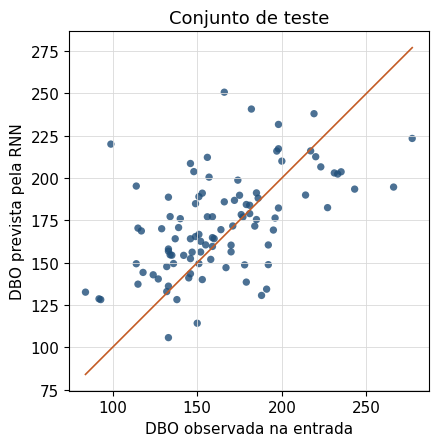

In [9]:
def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nome}.pdf")
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150)
    plt.show()


fig, ax = plt.subplots()
ax.scatter(y_teste, y_rnn, s=28, alpha=0.8, c=COR, edgecolors="none")
limites = [min(y_teste.min(), y_rnn.min()), max(y_teste.max(), y_rnn.max())]
ax.plot(limites, limites, color=COR_REF, linewidth=1.2)
ax.set_xlabel("DBO observada na entrada")
ax.set_ylabel("DBO prevista pela RNN")
ax.set_title("Conjunto de teste")
ax.set_aspect("equal", adjustable="box")
salvar(fig, "rnn_dbo_anteriores_observado")


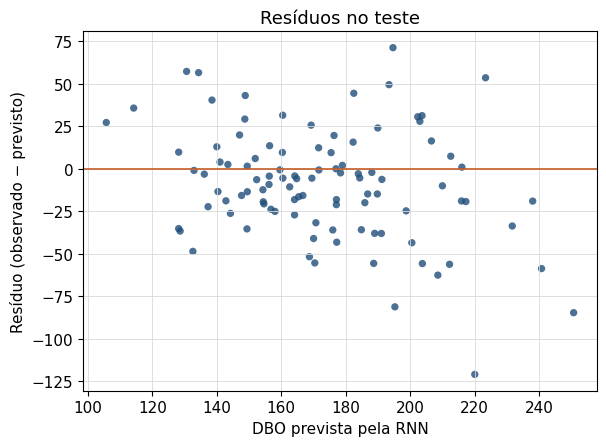

In [10]:
fig, ax = plt.subplots()
ax.scatter(y_rnn, residuo, s=28, alpha=0.8, c=COR, edgecolors="none")
ax.axhline(0, color=COR_REF, linewidth=1.2)
ax.set_xlabel("DBO prevista pela RNN")
ax.set_ylabel("Resíduo (observado − previsto)")
ax.set_title("Resíduos no teste")
salvar(fig, "rnn_dbo_anteriores_residuos")


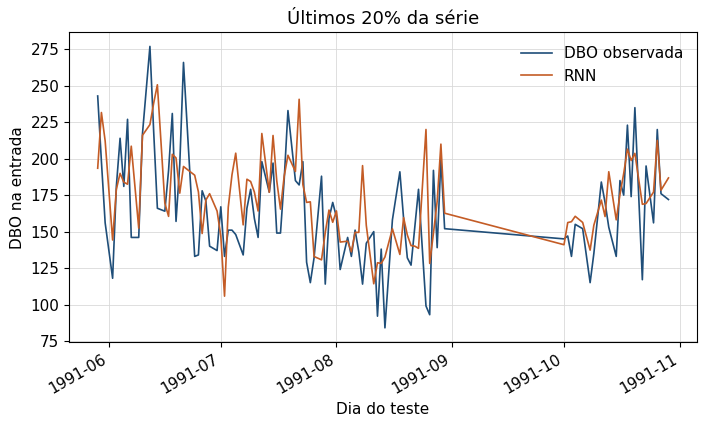

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(data_teste, y_teste, color=COR, linewidth=1.2, label="DBO observada")
ax.plot(data_teste, y_rnn, color=COR_REF, linewidth=1.2, label="RNN")
ax.set_xlabel("Dia do teste")
ax.set_ylabel("DBO na entrada")
ax.set_title("Últimos 20% da série")
ax.legend(frameon=False)
fig.autofmt_xdate()
salvar(fig, "rnn_dbo_anteriores_serie")


## Leitura

No teste cronológico, de 29 de maio a 29 de outubro de 1991, a RNN tem MAE 25,69, RMSE 33,52 e R² 0,16. A regressão linear com as 10 DBO anteriores mais a DQO e o SST do dia tem MAE 26,86 e RMSE 34,41. A validação temporal escolheu estado de 8 unidades e taxa 0,01, com MAE 40,20 ± 2,77.

A DBO medida imediatamente anterior, sozinha, tem MAE 35,85. O que reduz o erro é a fila de 10 DBO junto com a DQO do dia. O SST continua sem peso. A análise escrita está em `docs/rnn_dbo_anteriores.pdf`.
